/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 24, 24, 16)     │           416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 12, 12, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        23,050 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,466 (91.66 KB)

 Trainable params: 23,466 (91.66 KB)

 Non-trainable params: 0 (0.00 B)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 20s 166ms/step - accuracy: 0.8226 - loss: 4.2380
Epoch 2/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 21s 181ms/step - accuracy: 0.9533 - loss: 0.3288
Epoch 3/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 40s 169ms/step - accuracy: 0.9710 - loss: 0.1390
Epoch 4/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 18s 153ms/step - accuracy: 0.9797 - loss: 0.0854
Epoch 5/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 18s 155ms/step - accuracy: 0.9847 - loss: 0.0562
Epoch 6/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 22s 168ms/step - accuracy: 0.9870 - loss: 0.0437
Epoch 7/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 19s 158ms/step - accuracy: 0.9904 - loss: 0.0334
Epoch 8/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 22s 168ms/step - accuracy: 0.9916 - loss: 0.0273
Epoch 9/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 18s 153ms/step - accuracy: 0.9929 - loss: 0.0228
Epoch 10/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 18s 155ms/step - accuracy: 0.9943 - loss: 0.0186
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.981

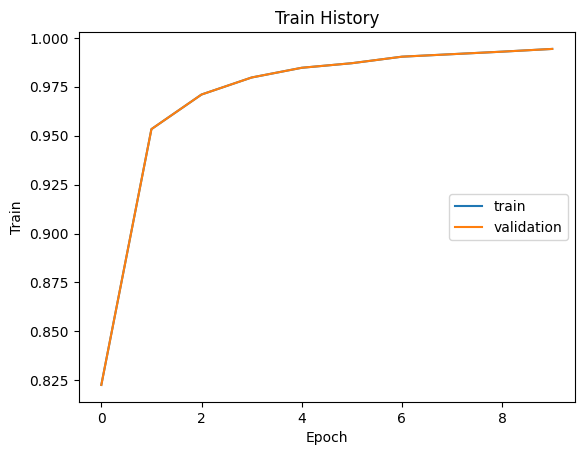

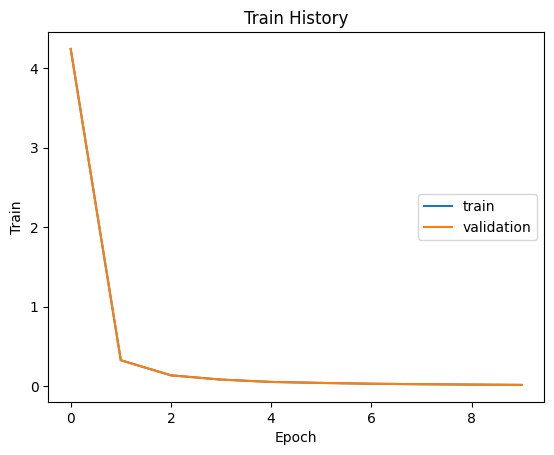

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step
(10000, 10)


predict,0,1,2,3,4,5,6,7,8,9
label,,,,,,,,,,
0,969,0,2,0,0,0,4,1,3,1
1,0,1122,2,2,4,0,1,1,3,0
2,2,3,1011,1,1,0,1,8,5,0
3,0,0,6,987,0,10,0,2,5,0
4,0,1,1,0,965,0,3,3,2,7
5,2,0,0,7,0,874,5,0,2,2
6,2,1,1,1,2,2,942,0,7,0
7,0,2,6,3,3,0,0,1012,1,1
8,2,0,3,4,3,1,0,0,959,2


In [1]:
#1
from tensorflow import keras
# 從 TensorFlow 匯入 Keras 深度學習工具
from keras.models import Sequential
# 匯入 Sequential 順序式模型
from keras.layers import Dense, Conv2D, MaxPooling2D, Flatten
# 匯入神經網路所需的層
model=Sequential()
# 建立 Sequential 順序式神經網路模型
model.add(Conv2D(filters=16, kernel_size=(5, 5), input_shape=(28, 28, 1), activation='relu'))
# 加入第一個卷積層
model.add(MaxPooling2D(pool_size=(2, 2)))
# 加入最大池化層
#model.add(Conv2D(filters=36, kernel_size=(5, 5), activation='relu'))
#model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Flatten())
# 加入 Flatten 展平層
model.add(Dense(10, activation='softmax'))
# 加入輸出層
model.summary()
# 顯示神經網路模型的架構、各層輸出形狀及參數數量
model.compile(optimizer='rmsprop', loss='categorical_crossentropy', metrics=['accuracy'])
# 編譯神經網路模型，設定訓練參數

#2
mnist=keras.datasets.mnist
# 取得 Keras 內建的 MNIST 手寫數字資料集
(train_data, train_label), (test_data, test_label) = mnist.load_data()
# 載入訓練資料及測試資料
test_label_original=test_label #for crosstab
# 保留尚未進行 One-Hot 編碼的原始測試標籤
train_label = keras.utils.to_categorical(train_label)
test_label = keras.utils.to_categorical(test_label)
# 將圖片像素值由 0～255 正規化成 0～1

#3
train_history=model.fit(train_data,train_label,epochs=10,batch_size=512)
# 使用訓練圖片及對應標籤進行模型訓練

#4
score=model.evaluate(test_data, test_label)
# 使用測試圖片及標籤評估模型的表現
print(score[1])
# 印出模型在測試資料上的準確率

#5
#繪製正確性與損失立歷史圖
import matplotlib.pyplot as plt
# 匯入 Matplotlib 繪圖套件
import numpy as np
# 匯入 NumPy 數值運算套件

def show_train_history(train_history, train, validation):
 # 定義繪製訓練歷史圖的函式
    plt.plot(train_history.history[train])
 # 繪製訓練資料的數值變化曲線
    plt.plot(train_history.history[validation])
 # 繪製驗證資料的數值變化曲線
    plt.title('Train History')
 # 設定圖表標題
    plt.ylabel('Train')
 # 設定 Y 軸名稱
    plt.xlabel('Epoch')
 # 設定 X 軸名稱
    plt.legend(['train', 'validation'], loc='center right')
 # 顯示圖例，區分訓練資料與驗證資料
    plt.show()
 # 顯示圖表

show_train_history(train_history, 'accuracy', 'accuracy')
# 繪製訓練準確率與驗證準確率的變化圖
show_train_history(train_history, 'loss', 'loss')
# 繪製訓練損失值與驗證損失值的變化圖

# Confusion Matrix混淆矩陣
import pandas as pd
prediction = model.predict(test_data)
prediction_label=np.argmax(prediction,axis=1)
print(test_label.shape)
pd.crosstab(test_label_original, prediction_label, rownames=['label'], colnames=['predict'])